# Product Category & Customer Rating Analysis

## 1. Introduction

This notebook analyzes product category fulfillment
performance and the relationship between delivery delays
and customer satisfaction.

### Objectives

1. Analyze delivery duration across product categories.
2. Compare cancellation rates across product categories.
3. Investigate customer rating patterns across delivery delays.
4. Identify how increasing delivery delays are associated
   with negative customer reviews.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading and Initial Inspection

In [14]:
# Load the analytical dataset
df = pd.read_csv(
    '../data/interim/logistics_analytical_dataset.csv'
)

print("Dataset loaded successfully!")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 99441
Number of columns: 39


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,has_invalid_timestamps,is_delivered,...,total_weight_g,review_score,min_review_score,review_count,has_review_comment,is_interstate,purchase_year,purchase_year_month,purchase_weekday,purchase_hour
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,True,...,500.0,4.0,4.0,1.0,1.0,False,2017,2017-10,Monday,10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,True,...,400.0,4.0,4.0,1.0,1.0,True,2018,2018-07,Tuesday,20
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,True,...,420.0,5.0,5.0,1.0,0.0,True,2018,2018-08,Wednesday,8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,True,...,450.0,5.0,5.0,1.0,1.0,True,2017,2017-11,Saturday,19
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,True,...,250.0,5.0,5.0,1.0,0.0,False,2018,2018-02,Tuesday,21


In [15]:
# Display all available columns
print("Dataset Columns:\n")

for col in df.columns:
    print(col)

Dataset Columns:

order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
has_invalid_timestamps
is_delivered
is_canceled
is_valid_delivered
is_eligible_otd
order_processing_time_days
carrier_transit_time_days
total_delivery_duration_days
promised_delivery_duration_days
delay_days
delivery_outcome
customer_state
customer_city
customer_zip_code_prefix
order_item_count
total_order_value
total_freight_value
primary_category
seller_state
seller_city
seller_id
total_weight_g
review_score
min_review_score
review_count
has_review_comment
is_interstate
purchase_year
purchase_year_month
purchase_weekday
purchase_hour


In [16]:
# Identify category-related columns
category_cols = [
    col for col in df.columns
    if 'category' in col.lower()
]

print("Category-related columns:")
print(category_cols)

# Inspect category information
for col in category_cols:
    print(f"\nColumn: {col}")
    print("Unique categories:", df[col].nunique())
    display(df[col].value_counts().head(10))

Category-related columns:
['primary_category']

Column: primary_category
Unique categories: 74


primary_category
bed_bath_table           9311
health_beauty            8796
sports_leisure           7681
computers_accessories    6660
furniture_decor          6355
housewares               5829
watches_gifts            5601
telephony                4182
auto                     3880
toys                     3861
Name: count, dtype: int64

In [17]:
# Check for English category column
if 'product_category_name_english' in df.columns:
    print("English category translations found!")

    display(
        df['product_category_name_english']
        .value_counts()
        .head(15)
    )
else:
    print("English category column not found.")
    print("We need to inspect the available category columns.")

English category column not found.
We need to inspect the available category columns.


## 3. Data Quality and Category Inspection

In [18]:
print("Dataset shape:", df.shape)

print("\nMissing values in important columns:")

important_cols = [
    'order_id',
    'primary_category',
    'order_status',
    'is_canceled',
    'is_eligible_otd',
    'total_delivery_duration_days',
    'delay_days',
    'review_score'
]

display(
    df[important_cols]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

# Check category distribution
print("\nNumber of unique categories:",
      df['primary_category'].nunique())

print("\nTop 15 categories by order volume:")

display(
    df['primary_category']
    .value_counts()
    .head(15)
)

Dataset shape: (99441, 39)

Missing values in important columns:


,Missing Values
order_id,0
primary_category,775
order_status,0
is_canceled,0
is_eligible_otd,0
total_delivery_duration_days,2972
delay_days,2972
review_score,768



Number of unique categories: 74

Top 15 categories by order volume:


primary_category
bed_bath_table           9311
health_beauty            8796
sports_leisure           7681
computers_accessories    6660
furniture_decor          6355
housewares               5829
watches_gifts            5601
telephony                4182
auto                     3880
toys                     3861
cool_stuff               3603
garden_tools             3482
perfumery                3149
baby                     2839
electronics              2540
Name: count, dtype: int64

## 4. Product Category Fulfillment Analysis

This section investigates differences in order fulfillment
performance across product categories.

The top 15 categories are selected based on order volume.
We compare cancellation rates and delivery duration to
identify categories with potentially greater fulfillment
complexity.

In [28]:
# Prepare category-level data

# Keep all orders for cancellation analysis
category_data = df.copy()

# Identify cancellation and unavailability
cancelled = (
    category_data['is_canceled']
    .fillna(0)
    .astype(bool)
)

unavailable = category_data['order_status'].eq('unavailable')

category_data['is_cancelled_or_unavailable'] = (
    cancelled | unavailable
)

# Top 15 categories by total order volume
top_categories = (
    category_data['primary_category']
    .value_counts()
    .head(15)
    .index
)

category_data = category_data[
    category_data['primary_category'].isin(top_categories)
]

# Cancellation statistics
category_summary = (
    category_data.groupby('primary_category')
    .agg(
        total_orders=('order_id', 'count'),
        cancelled_orders=(
            'is_cancelled_or_unavailable', 'sum'
        ),
        cancellation_rate=(
            'is_cancelled_or_unavailable', 'mean'
        )
    )
)

category_summary['cancellation_rate_pct'] = (
    category_summary['cancellation_rate'] * 100
)

# Delivery duration: eligible delivered orders only
valid = df[
    (df['is_eligible_otd'] == 1)
].copy()

delivery_summary = (
    valid[
        valid['primary_category'].isin(top_categories)
    ]
    .groupby('primary_category')
    .agg(
        delivered_orders=('order_id', 'count'),
        mean_delivery_days=(
            'total_delivery_duration_days', 'mean'
        ),
        median_delivery_days=(
            'total_delivery_duration_days', 'median'
        )
    )
)

# Combine both analyses
category_summary = category_summary.join(
    delivery_summary,
    how='left'
)

category_summary = category_summary.sort_values(
    'total_orders',
    ascending=False
)

display(category_summary.round(2))

,total_orders,cancelled_orders,cancellation_rate,cancellation_rate_pct,delivered_orders,mean_delivery_days,median_delivery_days
primary_category,,,,,,,
bed_bath_table,9311,18,0.00,0.19,9145,13.05,10.78
health_beauty,8796,35,0.00,0.40,8592,12.11,9.59
sports_leisure,7681,47,0.01,0.61,7479,12.27,10.13
computers_accessories,6660,35,0.01,0.53,6489,13.20,11.12
furniture_decor,6355,24,0.00,0.38,6194,13.12,10.90
housewares,5829,37,0.01,0.63,5678,11.12,8.93
watches_gifts,5601,20,0.00,0.36,5460,12.83,10.36
telephony,4182,16,0.00,0.38,4072,12.97,10.82
auto,3880,25,0.01,0.64,3775,12.36,9.79


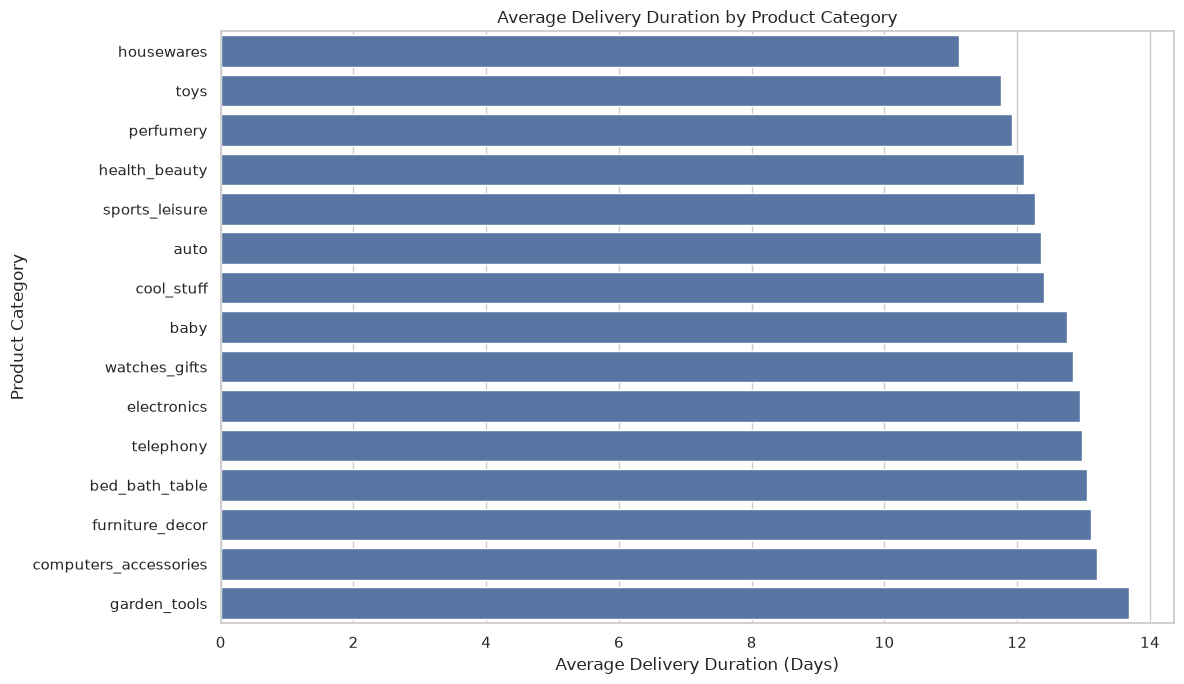

In [29]:
plt.figure(figsize=(12, 7))

plot_data = category_summary.sort_values(
    'mean_delivery_days',
    ascending=True
)

sns.barplot(
    data=plot_data,
    x='mean_delivery_days',
    y=plot_data.index
)

plt.title(
    'Average Delivery Duration by Product Category'
)
plt.xlabel('Average Delivery Duration (Days)')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

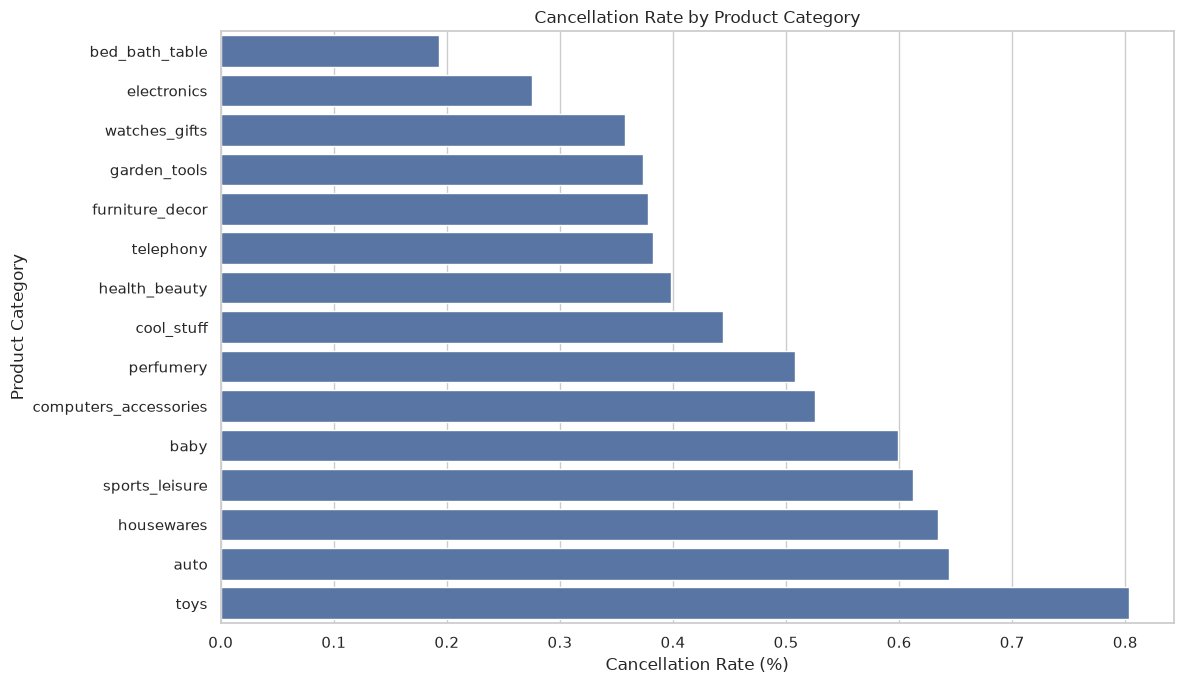

In [30]:
plt.figure(figsize=(12, 7))

plot_data = category_summary.sort_values(
    'cancellation_rate_pct',
    ascending=True
)

sns.barplot(
    data=plot_data,
    x='cancellation_rate_pct',
    y=plot_data.index
)

plt.title(
    'Cancellation Rate by Product Category'
)
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [31]:
# Prepare rating analysis dataset

valid = df[
    (df['is_eligible_otd'] == 1)
].dropna(
    subset=['review_score', 'delay_days']
).copy()

valid['delay_days'] = pd.to_numeric(
    valid['delay_days'],
    errors='coerce'
)

valid['review_score'] = pd.to_numeric(
    valid['review_score'],
    errors='coerce'
)

valid = valid.dropna(
    subset=['delay_days', 'review_score']
)

print("Eligible orders with valid review scores:",
      len(valid))

Eligible orders with valid review scores: 95636


In [32]:
# Categorize delivery delays
def categorize_delay(days):

    if days <= 0:
        return '0. On-Time'

    elif days <= 3:
        return '1. 1-3 Days Late'

    elif days <= 7:
        return '2. 4-7 Days Late'

    else:
        return '3. >7 Days Late'


valid['delay_bucket'] = (
    valid['delay_days'].apply(categorize_delay)
)

print("Delay bucket distribution:")

display(
    valid['delay_bucket']
    .value_counts()
    .sort_index()
)

Delay bucket distribution:


delay_bucket
0. On-Time          87979
1. 1-3 Days Late     2634
2. 4-7 Days Late     1771
3. >7 Days Late      3252
Name: count, dtype: int64

In [33]:
# Calculate rating degradation

rating_decay = (
    valid.groupby('delay_bucket', observed=True)
    .agg(
        orders=('order_id', 'count'),

        mean_rating=('review_score', 'mean'),

        pct_1star=(
            'review_score',
            lambda x: (x == 1).mean() * 100
        ),

        pct_5star=(
            'review_score',
            lambda x: (x == 5).mean() * 100
        )
    )
)

display(rating_decay.round(2))

,orders,mean_rating,pct_1star,pct_5star
delay_bucket,,,,
0. On-Time,87979,4.29,6.55,62.39
1. 1-3 Days Late,2634,3.77,13.71,43.13
2. 4-7 Days Late,1771,2.32,53.02,18.07
3. >7 Days Late,3252,1.73,68.63,7.47


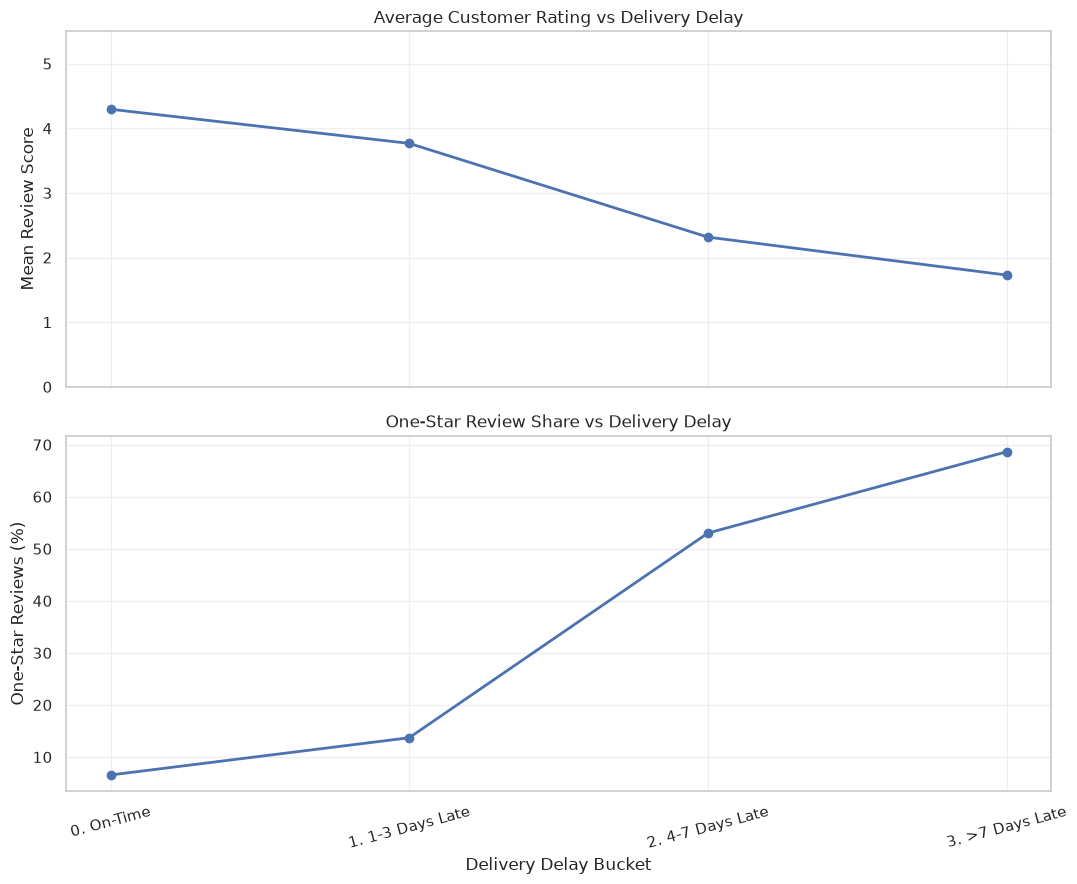

In [34]:
# Rating degradation visualization

import os

os.makedirs('../reports/figures', exist_ok=True)

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 9),
    sharex=True
)

# Mean rating
axes[0].plot(
    rating_decay.index,
    rating_decay['mean_rating'],
    marker='o',
    linewidth=2
)

axes[0].set_title(
    'Average Customer Rating vs Delivery Delay'
)

axes[0].set_ylabel('Mean Review Score')
axes[0].set_ylim(0, 5.5)
axes[0].grid(alpha=0.3)

# 1-star percentage
axes[1].plot(
    rating_decay.index,
    rating_decay['pct_1star'],
    marker='o',
    linewidth=2
)

axes[1].set_title(
    'One-Star Review Share vs Delivery Delay'
)

axes[1].set_ylabel('One-Star Reviews (%)')
axes[1].set_xlabel('Delivery Delay Bucket')
axes[1].grid(alpha=0.3)

plt.xticks(rotation=15)
plt.tight_layout()


plt.savefig(
    '../reports/figures/rating_decay_curve.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 5. Key Findings

- Mean review score declines from 4.29 (on-time) to 1.73 (>7 days late); the
  1-star share rises from 6.55% to 68.63%.
- The sharpest drop occurs between the 1-3 day and 4-7 day late buckets.
- Sample sizes: 87,979 on-time orders vs. 1,771–3,252 per late bucket
  (95,636 eligible orders with reviews).

## 6. Limitations and Causal Caveats

- This is an **association, not proof of causation**. Late delivery is
  correlated with low ratings, but delay is not the sole cause of bad reviews.
- Confounders likely include product quality, wrong or damaged items, seller
  communication, and product category.
- Reviews are voluntary, so unhappy customers may be over-represented
  (self-selection bias).
- Cancellation counts per category are small (e.g., 7–47 orders), so those rates
  should be interpreted cautiously.
- 775 orders have no category and were excluded from the category analysis.